# Phase 4 write-up: the "not transit-like" blind spot (11/14/2026)

After Phase 3, the largest error group left is the **"not transit-like" (NT) false positives**: signals that are
not a transit at all, such as detrending residuals, stellar variability, rolling-band noise and spacecraft events.
At the 98% planet-recall headline, about **seven in ten NT-only FPs still pass** (catalog family). The robovetter
caught the ones we miss with tests of three kinds:
- is the event **unique** in its own light curve;
- do the **individual transits agree**;
- do the transits fall on **bad times**, when many other stars show events too.

Phase 4 (`PHASE4_PLAN.md`, approved 11/13 with decisions N1–N5 as recommended) rebuilt label-free versions of those
tests as features and checked them by CV:

0. **Phase 3 adoption:** the "+ ephemeris" models are frozen (user decision, 11/13).
1. **M0, N-c:** bad-time clustering from the DR25 TCE list.
2. **M1, N-a + N-b:** uniqueness and per-transit consistency, one pass over our light curves.
3. **M2:** CV, paired against Phase 2a and against the adopted "+ ephemeris" models.
4. **Why it did not help:** an SNR-matched check.
5. **N-d:** alternative detrending, the plan's last feature group.
6. Conclusions.

**CV only.** The sealed test split is spent and is not used. Labels and robovetter comments only group KOIs for
analysis; they are never inputs.

In [1]:
include(joinpath(@__DIR__, "..", "src", "VettingSetup.jl"))
df_raw = load_koi()
pool, _ = cv_pool(clean_koi(df_raw))
y = Float64.(pool.label)
dr = is_dr25(pool, df_raw)
vi = with_vetting_info(pool, df_raw, zeros(nrow(pool)))
fpat = vi.flag_pattern
nt = (y .== 0) .& (fpat .== "NT")
readres(f) = CSV.read(joinpath(CV_DIR, f), DataFrame)
pool = leftjoin(pool, readres("p2_lcfeatures.csv"); on = :kepoi_name, order = :left)
pool = leftjoin(pool, readres("p4_badtimes.csv")[:, [:kepoi_name; BADTIME_FEATURES]]; on = :kepoi_name, order = :left)
pool = leftjoin(pool, readres("p4_ntfeatures.csv"); on = :kepoi_name, order = :left)
pool = leftjoin(pool, readres("p4_ndfeatures.csv"); on = :kepoi_name, order = :left)
S = (repeat_scores(load_cv("cv_mlpq_eph_r5s10.jld2")) .+ repeat_scores(load_cv("cv_evotree_eph_r5s10.jld2"))) ./ 2
s_eph = vec(mean(S; dims = 2))                    # "+ ephemeris" catalog model, mean OOF score
missed = nt .& (s_eph .>= 0.5)
@printf("pool: %d KOIs; NT-only FPs %d (DR25 %d); missed at p = 0.5 by \"+ ephemeris\": %d\n",
        nrow(pool), sum(nt), sum(nt .& dr), sum(missed))

VettingSetup loaded:11 features, data at C:\JuliaProjects\Exoplanet vetting\data\koi_cumulative.csv
┌ Info: clean_koi
│   raw = 9564
│   kept = 9201
│   stars = 7927
│   planets = 4619
└   false_pos = 4582
pool: 8288 KOIs; NT-only FPs 849 (DR25 433); missed at p = 0.5 by "+ ephemeris": 173


## 0. Phase 3 adopted and frozen

On 11/13 the user adopted the "+ ephemeris" models. `sweeps/p3_freeze.jl` trained both of them on the whole pool,
the same way as the Phase 2 freeze: 10 MLP and 10 tree seeds, a fixed inner split, and menu thresholds from the
nested CV, picked on DR25 KOIs. They are saved in `models/p3_frozen.jld2` under the keys `catalog_ephemeris` and
`centroid_ephemeris`, with no calibrator. They are labelled **post-test, CV-validated**: the test split was never
scored with them.

In [2]:
fz = JLD2.load(joinpath(MODEL_DIR, "p3_frozen.jld2"))["frozen"]
DataFrame([(model = k, n_features = length(fz[k]["features"]),
            t_recall98 = round(fz[k]["thresholds"]["(:recall, 0.98)"]; digits = 3),
            t_recall95 = round(fz[k]["thresholds"]["(:recall, 0.95)"]; digits = 3),
            t_maxF1 = round(fz[k]["thresholds"]["(:maxf1,)"]; digits = 3)) for k in ("catalog_ephemeris", "centroid_ephemeris")])

┌ Warning: type Main.TreeVetter does not exist in workspace; interpreting Array{Main.TreeVetter} as Array{Any}
└ @ JLD2 C:\JuliaDEPOT\packages\JLD2\rm5a0\src\datasets.jl:128
┌ Warning: type Main.TreeVetter does not exist in workspace; reconstructing
└ @ JLD2 C:\JuliaDEPOT\packages\JLD2\rm5a0\src\data\reconstructing_datatypes.jl:588


Row,model,n_features,t_recall98,t_recall95,t_maxF1
,String,Int64,Float64,Float64,Float64
1,catalog_ephemeris,28,0.204,0.402,0.541
2,centroid_ephemeris,37,0.261,0.51,0.601


## 1. M0 (N-c): do the transits fall on bad times?

**Sources:** the 29,180 DR25 TCEs with P ≥ 1 d. Their predicted transit midpoints are counted in 0.25-d bins and
smoothed to 0.75-d windows. Each TCE carries a total weight of 1, spread over its transits. Without that weighting,
the short-period TCEs fill every bin and hide all time structure: that version showed no excess at all over the
null.

**Null:** every TCE epoch is shifted by a random fraction of its period.

**Features** (`src/BadTimes.jl`):
- **Global:** the robust z of each window, with the target's own star removed.
- **Local:** a Poisson significance from TCEs on other stars within 30′, roughly the same CCD channel.
- Each is given per KOI as a mean over its transits and as the fraction of its transits in bad windows.

windows with z > 4: real 77, null 1


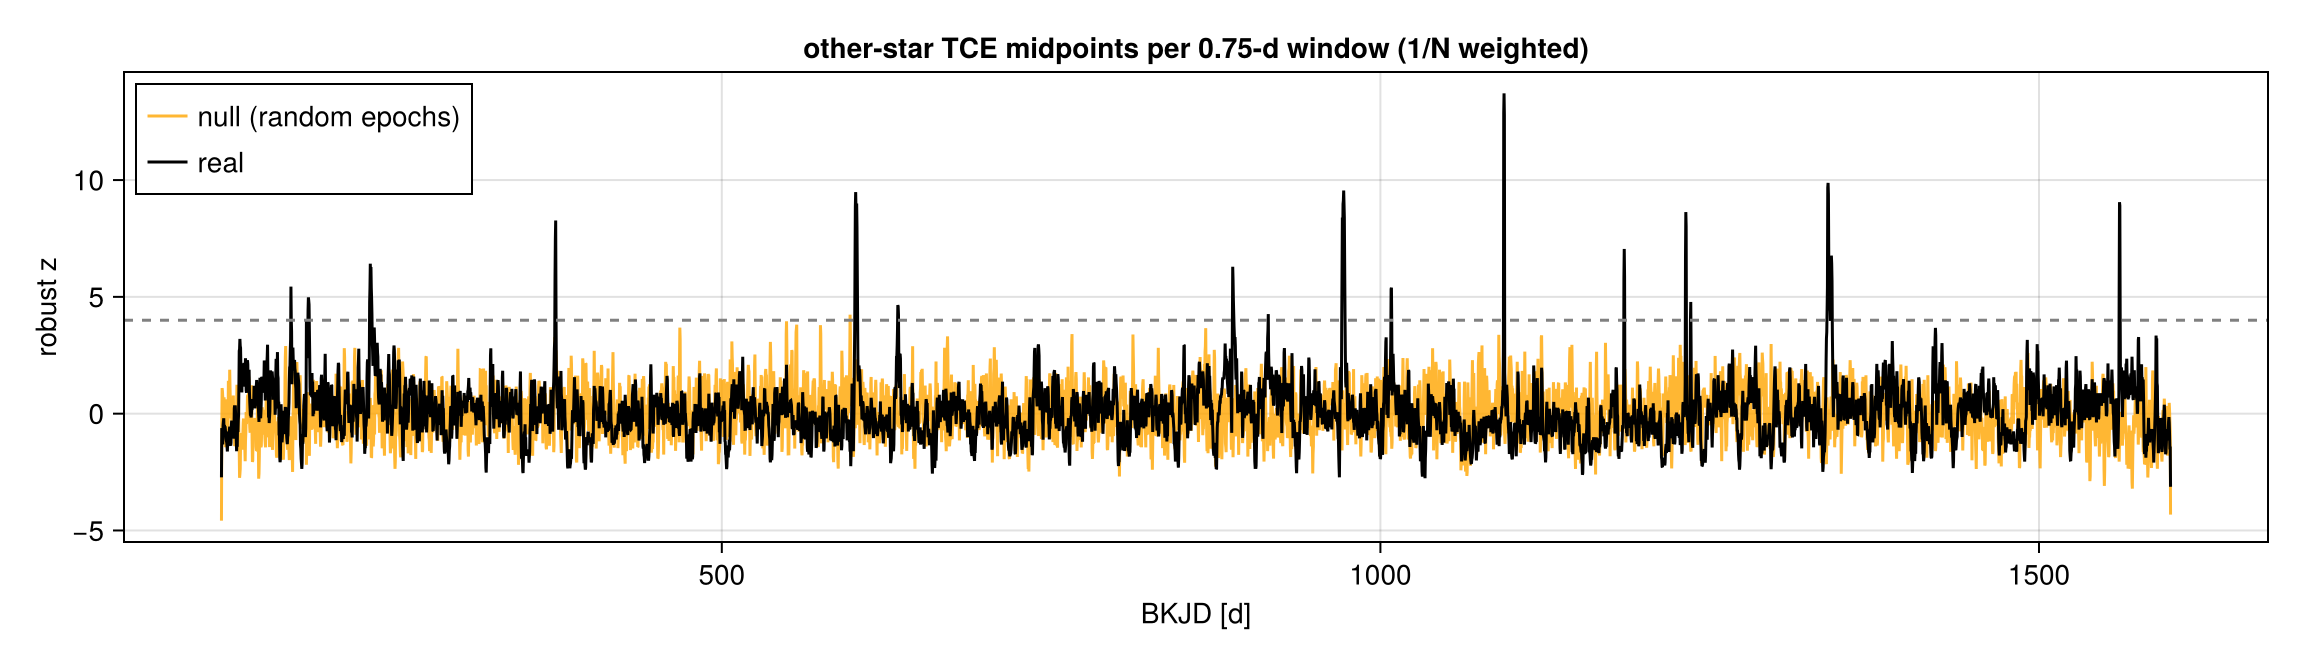

In [3]:
ser = readres("p4_badtimes_series.csv")
fig = Figure(size = (1150, 330))
ax = Axis(fig[1, 1]; xlabel = "BKJD [d]", ylabel = "robust z", title = "other-star TCE midpoints per 0.75-d window (1/N weighted)")
lines!(ax, ser.bkjd, ser.null_z; color = (:orange, 0.8), label = "null (random epochs)")
lines!(ax, ser.bkjd, ser.z; color = :black, label = "real")
hlines!(ax, [BT_ZCUT]; color = :gray, linestyle = :dash); axislegend(ax; position = :lt)
@printf("windows with z > %.0f: real %d, null %d\n", BT_ZCUT, sum(ser.z .> BT_ZCUT), sum(ser.null_z .> BT_ZCUT))
fig

The real series has **77 bad windows (z > 4, 22 above z = 8)** against 0–5 in random-epoch nulls. The worst are
at BKJD ≈ 1094, 1340, 602, 972 and 1561. Locally, 905 KOIs have a transit in a bad window, against ~60 in the null.
So the clustering is real.

**But it is not what the missed NT FPs have in common** (`sweeps/results/p4_badtimes_classes.log`):
- Only 99 pool FPs carry the robovetter's SKYE comment.
- The missed NT-only FPs sit in bad windows *less* often than the caught ones.
- Single-feature AUC, NT-only FPs vs planets: 0.57–0.58 (global), ~0.51 (local).

## 2. M1 (N-a + N-b): uniqueness and per-transit consistency

One pass over the cached light curves with the Phase 2 detrending (`sweeps/p4_ntfeatures.jl`, 33 min at 2 threads,
2.1 GB). Every quantity is a significance against the same empirical box noise as the Phase 2 features.

| Feature | Meaning |
|---|---|
| `nt_red` | red-noise factor: transit-timescale noise / point-to-point noise |
| `nt_pos_sig`, `nt_ter_sig` | strongest off-transit bump, and strongest dip away from the secondary [σ] |
| `nt_ms_ter`, `nt_ms_pos` | primary SNR minus those (model-shift-like uniqueness) |
| `nt_chi2` | log10 reduced χ² of the individual transit depths |
| `nt_negfrac` | fraction of transits with negative depth |
| `nt_chases` | median over transits: its SNR vs the strongest dip within ±5 durations |
| `nt_rubble` | median fraction of the expected in-transit cadences actually observed |

┌ Warning: Assignment to `ax` in soft scope is ambiguous because a global variable by the same name exists: `ax` will be treated as a new local. Disambiguate by using `local ax` to suppress this warning or `global ax` to assign to the existing global variable.
└ @ C:\JuliaProjects\Exoplanet vetting\notebooks\exo111426.ipynb:6


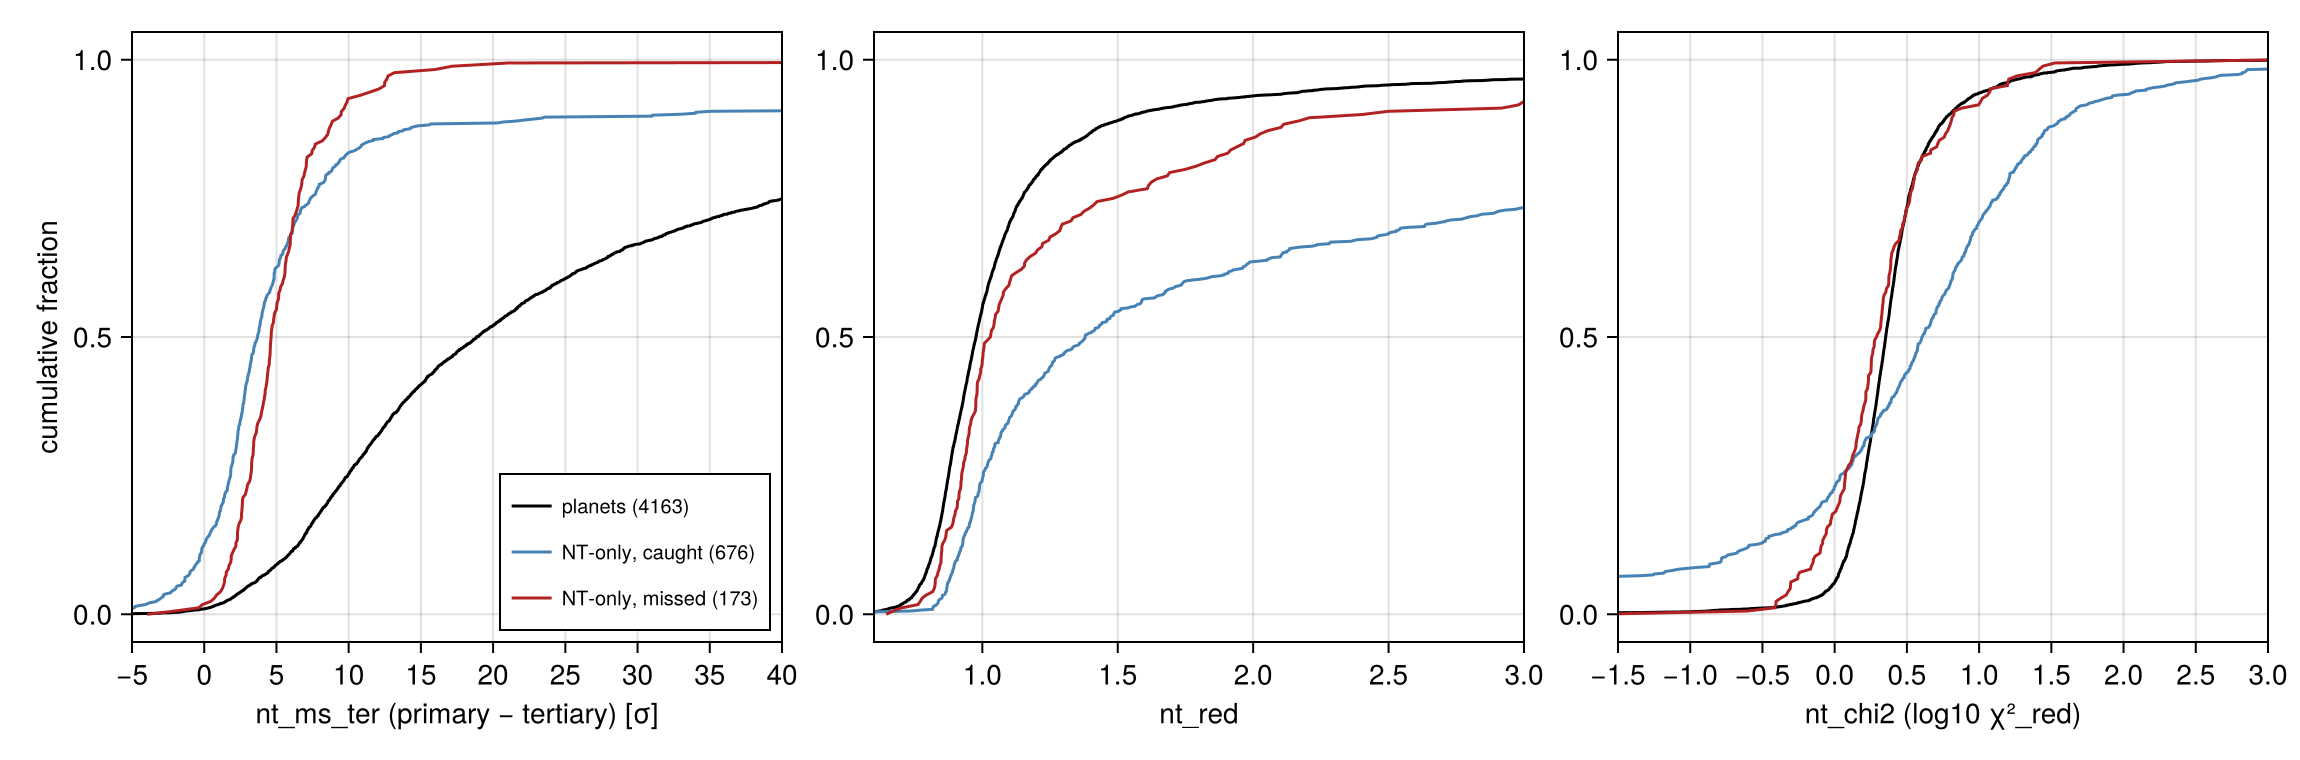

In [4]:
classes = [("planets", y .== 1, :black), ("NT-only, caught", nt .& .!missed, :steelblue),
           ("NT-only, missed", missed, :firebrick)]
fig = Figure(size = (1150, 380))
for (j, (c, lab, xl)) in enumerate(((:nt_ms_ter, "nt_ms_ter (primary − tertiary) [σ]", (-5, 40)),
                                    (:nt_red, "nt_red", (0.6, 3)), (:nt_chi2, "nt_chi2 (log10 χ²_red)", (-1.5, 3))))
    ax = Axis(fig[1, j]; xlabel = lab, ylabel = j == 1 ? "cumulative fraction" : "")
    for (name, m, col) in classes
        v = sort(filter(isfinite, Float64.(coalesce.(pool[!, c][m], NaN))))
        lines!(ax, v, range(0, 1; length = length(v)); color = col, label = "$name ($(sum(m)))")
    end
    xlims!(ax, xl...)
    j == 1 && axislegend(ax; position = :rb, labelsize = 10)
end
fig

On their own, the uniqueness features separate the missed NT FPs from planets well (`nt_ms_ter` AUC 0.89), and
`nt_red` separates NT FPs as a whole (0.78). The per-transit checks are weak (0.50–0.58).

## 3. M2: CV against Phase 2a and against the adopted "+ ephemeris" models

All nine NT features (bad times + M1) added to both families (N3). Same learners, hyperparameters and folds
(5 fold shuffles × 10 seeds; `sweeps/p4_cv.jl`, 8 runs, 34 min). Paired star bootstrap (`sweeps/p4_m2.jl`).

In [5]:
vcat(readres("p4_m2_summary.csv"), readres("p4_m2eph_summary.csv"))

Row,family,subset,n,old,auc_old,new,auc_new,delta,ci_lo,ci_hi
,DataStri…,DataStri…,Int64,DataStri…,Float64,DataStri…,Float64,Float64,Float64,Float64
1,catalog,DR25 KOIs,7199,Phase 2a,0.9705,+ NT,0.9736,0.0031,0.0019,0.0043
2,catalog,supplemental KOIs,1089,Phase 2a,0.6959,+ NT,0.7073,0.0113,-0.0023,0.0254
3,catalog,all pool,8288,Phase 2a,0.9536,+ NT,0.9576,0.0039,0.0026,0.0053
4,+ centroid,DR25 KOIs,7199,Phase 2a,0.9869,+ NT,0.9878,0.0008,0.0003,0.0013
5,+ centroid,supplemental KOIs,1089,Phase 2a,0.7661,+ NT,0.7673,0.0012,-0.008,0.0108
6,+ centroid,all pool,8288,Phase 2a,0.9752,+ NT,0.9763,0.0011,0.0004,0.0018
7,catalog,DR25 KOIs,7199,+ ephemeris,0.9764,+ eph + NT,0.977,0.0006,-0.0001,0.0012
8,catalog,supplemental KOIs,1089,+ ephemeris,0.6979,+ eph + NT,0.7107,0.0128,0.0008,0.0239
9,catalog,all pool,8288,+ ephemeris,0.9605,+ eph + NT,0.9617,0.0012,0.0004,0.0019


In [6]:
c1 = readres("p4_m2_criteria.csv"); c2 = readres("p4_m2eph_criteria.csv")
c1.lineage .= "vs Phase 2a"; c2.lineage .= "vs + ephemeris"
cc = vcat(c1, c2)
cc[in.(cc.group, Ref(("FP missed: NT only", "FP missed: NT only (DR25)", "FP missed: EC only", "FP missed: all",
                      "CONFIRMED called FP (DR25)"))) .& (cc.rule .== "planet recall 98%"),
   [:lineage, :group, :n, :family, :old_pct, :new_pct, :delta_pct, :ci_lo, :ci_hi]]

Row,lineage,group,n,family,old_pct,new_pct,delta_pct,ci_lo,ci_hi
,String,DataStri…,Int64,DataStri…,Float64,Float64,Float64,Float64,Float64
1,vs Phase 2a,FP missed: NT only,849,catalog,70.7,70.3,-0.4,-1.4,0.5
2,vs Phase 2a,FP missed: NT only,849,+ centroid,60.2,60.8,0.6,-0.5,1.8
3,vs Phase 2a,FP missed: NT only (DR25),433,catalog,54.6,54.2,-0.4,-1.8,0.9
4,vs Phase 2a,FP missed: NT only (DR25),433,+ centroid,49.3,50.4,1.1,-0.3,2.6
5,vs Phase 2a,FP missed: EC only,111,catalog,44.3,26.8,-17.5,-24.1,-11.2
6,vs Phase 2a,FP missed: EC only,111,+ centroid,33.7,28.5,-5.2,-8.8,-1.6
7,vs Phase 2a,FP missed: all,4125,catalog,33.0,31.6,-1.5,-2.0,-0.9
8,vs Phase 2a,FP missed: all,4125,+ centroid,20.4,20.1,-0.3,-0.7,0.1
9,vs Phase 2a,CONFIRMED called FP (DR25),2459,catalog,0.4,0.3,-0.0,-0.1,0.1


**Negative for NT, so criterion N5 is not met.**
- Against Phase 2a, DR25 AUC rises **+0.003** (catalog) and **+0.001** (+ centroid), both with CIs above 0. But the
  gain comes from **contamination** FPs: EC-only misses at p = 0.5 fall 18.0 → 9.7% and 23.2 → 15.7%. Contaminated
  signals are inconsistent from transit to transit, and the per-transit features see that.
- **NT-only misses do not move:** at 98% recall they go 70.7 → 70.3% (catalog) and 60.2 → 60.8% (+ centroid),
  with CIs spanning 0.
- Against the adopted "+ ephemeris" models, which already catch contamination, the AUC change is ≈ 0 (CIs include
  0). NT misses are unchanged, or slightly worse in the + centroid family at 98% recall (59.7 → 61.9%).
- No CONFIRMED regression anywhere.

## 4. Why: the information was already there

The missed NT FPs are low-SNR (median ~8). So the question is whether the new features separate NT FPs from planets
**at the same SNR**, and whether they do so better than the Phase 2 features the models already have
(`sweeps/p4_snrmatched.jl`).

In [7]:
snr = Float64.(coalesce.(pool.koi_model_snr, NaN))
rows = NamedTuple[]
for c in [:lc_snr, :lc_sev_ratio, :lc_sec_sig, :lc_timing, :bt_glob_frac, :nt_red, :nt_ter_sig, :nt_ms_ter, :nt_chi2,
          :nt_negfrac, :nt_chases, LC_ND_FEATURES...]
    x = Float64.(coalesce.(pool[!, c], NaN))
    au = map([(7.0, 10.0), (10.0, 15.0), (15.0, 30.0)]) do (lo, hi)
        m = (lo .<= snr .< hi) .& ((y .== 1) .| nt) .& isfinite.(x)
        a = fast_auc(y[m], x[m]); round(max(a, 1 - a); digits = 3)
    end
    push!(rows, (feature = string(c), phase = startswith(string(c), "lc_") ? "Phase 2" : "Phase 4",
                 snr_7_10 = au[1], snr_10_15 = au[2], snr_15_30 = au[3]))
end
DataFrame(rows)

Row,feature,phase,snr_7_10,snr_10_15,snr_15_30
,String,String,Float64,Float64,Float64
1,lc_snr,Phase 2,0.69,0.761,0.793
2,lc_sev_ratio,Phase 2,0.764,0.874,0.814
3,lc_sec_sig,Phase 2,0.651,0.802,0.628
4,lc_timing,Phase 2,0.686,0.71,0.593
5,bt_glob_frac,Phase 4,0.614,0.689,0.6
6,nt_red,Phase 4,0.618,0.775,0.867
7,nt_ter_sig,Phase 4,0.725,0.848,0.682
8,nt_ms_ter,Phase 4,0.75,0.86,0.933
9,nt_chi2,Phase 4,0.612,0.681,0.653


The new features **do** separate NT FPs from planets at matched SNR: `nt_ms_ter` has AUC 0.75 / 0.86 / 0.93. But
the Phase 2 features already reach similar values: `lc_sev_ratio` (single-event dominance) 0.76 / 0.87 / 0.81, and
`lc_sec_sig` (the strongest other dip) 0.65 / 0.80 / 0.63. Uniqueness and dominance measure much the same thing,
so the models gain nothing new. The NT FPs that still pass are the ones that **none** of these measurements tells
apart from low-SNR planets.

## 5. N-d: alternative detrending

A systematic often lives at one timescale: a slow wiggle that a short detrending window absorbs, or a dip that
exists only because a long window leaves a trend in place. N-d re-measures each KOI's box depth and SNR twice
(`LC_ND_FEATURES`, `sweeps/p4_ntfeatures.jl --nd`, 1.6 h, 2.1 GB):
- **short:** biweight with a window of max(0.25 d, 2.5 transit durations), the KOI itself not masked, so a long
  smooth "transit" is partly eaten;
- **long:** biweight with a window of max(2 d, 10 durations), all KOIs masked.

Each is given as a ratio to the default (Phase 2) detrending. Then 4 CV runs on the "+ ephemeris" lineage
(`sweeps/p4_cv.jl ephnd_* centephnd_*`, 16 min) and the same analysis (`sweeps/p4_m2.jl --nd`).

In [8]:
DataFrame([(group = g, n = sum(m), (c => round(median(filter(isfinite, Float64.(coalesce.(pool[!, c][m], NaN))));
                                              digits = 3) for c in LC_ND_FEATURES)...)
           for (g, m) in [("planets", y .== 1), ("NT-only, caught", nt .& .!missed), ("NT-only, missed", missed),
                          ("SS-only FPs", (y .== 0) .& (fpat .== "SS"))]])

Row,group,n,nd_dep_short,nd_snr_short,nd_dep_long,nd_snr_long
,String,Int64,Float64,Float64,Float64,Float64
1,planets,4163,0.619,0.699,1.0,0.773
2,"NT-only, caught",676,0.601,0.677,1.0,0.698
3,"NT-only, missed",173,0.594,0.684,0.984,0.756
4,SS-only FPs,1307,0.99,1.159,1.0,0.445


In [9]:
readres("p4_m2nd_summary.csv")

Row,family,subset,n,old,auc_old,new,auc_new,delta,ci_lo,ci_hi
,DataStri…,DataStri…,Int64,DataStri…,Float64,DataStri…,Float64,Float64,Float64,Float64
1,catalog,DR25 KOIs,7199,+ ephemeris,0.9764,+ eph + ND,0.9765,0.0,-0.0003,0.0004
2,catalog,supplemental KOIs,1089,+ ephemeris,0.6979,+ eph + ND,0.7016,0.0037,-0.0049,0.012
3,catalog,all pool,8288,+ ephemeris,0.9605,+ eph + ND,0.9607,0.0002,-0.0003,0.0007
4,+ centroid,DR25 KOIs,7199,+ ephemeris,0.9889,+ eph + ND,0.9891,0.0001,-0.0,0.0003
5,+ centroid,supplemental KOIs,1089,+ ephemeris,0.769,+ eph + ND,0.7709,0.0019,-0.0038,0.0075
6,+ centroid,all pool,8288,+ ephemeris,0.9778,+ eph + ND,0.978,0.0002,-0.0001,0.0005


In [10]:
c3 = readres("p4_m2nd_criteria.csv")
c3[in.(c3.group, Ref(("FP missed: NT only", "FP missed: NT only (DR25)", "FP missed: CO only", "FP missed: all",
                      "CONFIRMED called FP (DR25)"))) .& (c3.rule .== "planet recall 98%"), :]

Row,group,n,family,rule,old_pct,new_pct,delta_pct,ci_lo,ci_hi
,DataStri…,Int64,DataStri…,DataStri…,Float64,Float64,Float64,Float64,Float64
1,FP missed: NT only,849,catalog,planet recall 98%,70.0,67.9,-2.1,-2.9,-1.3
2,FP missed: NT only,849,+ centroid,planet recall 98%,59.7,59.7,0.1,-0.7,0.9
3,FP missed: NT only (DR25),433,catalog,planet recall 98%,54.1,52.6,-1.5,-2.6,-0.5
4,FP missed: NT only (DR25),433,+ centroid,planet recall 98%,49.6,49.1,-0.4,-1.5,0.6
5,FP missed: CO only,464,catalog,planet recall 98%,66.2,64.6,-1.6,-2.5,-0.8
6,FP missed: CO only,464,+ centroid,planet recall 98%,11.9,11.9,0.0,-0.5,0.5
7,FP missed: all,4125,catalog,planet recall 98%,28.7,27.9,-0.8,-1.1,-0.6
8,FP missed: all,4125,+ centroid,planet recall 98%,18.5,18.6,0.0,-0.2,0.3
9,CONFIRMED called FP (DR25),2459,catalog,planet recall 98%,0.4,0.4,0.0,-0.1,0.1


- Planets and NT FPs have nearly the same ratios. The short window removes about 40% of the depth for both, so
  the single-feature AUCs are only 0.50–0.58, also within SNR bins (table in §4). The features mainly flag
  secondary-eclipse FPs, whose depth is unchanged by the short window and whose long-window SNR drops.
- **CV:** DR25 AUC is unchanged (Δ +0.0000 catalog, +0.0001 + centroid; CIs include 0).
- **Catalog family at 98% recall:** NT-only misses 70.0 → **67.9%** (−2.1 points, CI [−2.9, −1.3]; DR25 KOIs
  54.1 → 52.6%), centroid-only misses −1.6 points, all FPs kept 28.7 → 27.9%. Small but real.
- **+ centroid family:** no change (NT 59.7 → 59.7%).
- No CONFIRMED regression. Criterion N5 (a 10-point drop) is **not met**.

## 6. Conclusions

- **All four planned feature groups were built and tested, and none closes the NT blind spot.** The best result is
  N-d's 2-point drop in the catalog family; N-a to N-c help only with contamination, which "+ ephemeris" had
  already fixed.
- **The information is mostly there already.** At matched SNR, uniqueness and per-transit tests do separate NT
  FPs from planets, but so do the Phase 2 features the models already use. The NT FPs that still pass at 98%
  recall look like low-SNR planets to every measurement we made.
- **What might still help** (not in this plan, not run): pixel-level information beyond the centroid, such as the
  per-pixel difference images. That is a much larger project.
- **Decision for the user:** the "+ ephemeris" models stay the adopted ones. The N-d features in the catalog family
  are the only candidate addition (−2 points NT, no cost elsewhere); adopting them, or none, is the user's call.